# 03 · What do users complain about? — Topic Modelling & Aspect Analysis

1. **Discover** (unsupervised): NMF on TF-IDF of negative reviews to find the main complaint topics.
2. **Measure** (rule-based): turn topics into aspect keyword lists (`src/momo_reviews/aspects.py`) — transparent, stable and trackable over time.
3. **Prioritise**: which aspects are both *frequently mentioned* and *most negative* → recommended actions.

Topic words and example reviews are in Vietnamese (the source language); aspect names are in English.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

from momo_reviews.config import CLEAN_FILE
from momo_reviews.viz import set_style, save, SENTIMENT_COLORS, BLUE, INK_2
set_style()
pd.set_option("display.max_colwidth", 160)

df = pd.read_parquet(CLEAN_FILE)
print(f"{len(df):,} reviews | {df['at'].min():%Y-%m-%d} → {df['at'].max():%Y-%m-%d}")
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from momo_reviews.aspects import aspect_matrix, ASPECTS

# Vietnamese stop words (function words, pronouns, fillers) + tokens introduced by normalisation
STOP = ["và", "là", "thì", "mà", "có", "của", "cho", "này", "đã", "được", "bị", "với", "các", "những", "một",
        "rồi", "lại", "cũng", "nữa", "khi", "để", "nên", "vì", "như", "ra", "vào", "lên", "đi", "làm", "rất",
        "quá", "nhưng", "hay", "thế", "gì", "vậy", "không", "tôi", "mình", "em", "anh", "chị", "bạn", "momo",
        "ứng", "dụng", "ứng dụng", "num", "neg_emoji", "pos_emoji", "nó", "ai", "sao", "nào", "luôn", "còn",
        "mới", "mãi", "thôi", "đâu", "ạ", "nha", "nhé", "ơi", "ko", "trong", "từ", "đến", "tại", "sẽ", "đang"]

217,357 reviews | 2014-05-28 → 2026-10-23


## 1. Topic modelling (NMF) on negative reviews

In [2]:
neg = df[(df["sentiment"] == "negative") & (df["n_words"] >= 4) & (~df["is_spam"])]
neg = neg[neg["at"] >= neg["at"].max() - pd.DateOffset(years=3)]   # last 3 years = issues that are still "alive"
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.5, stop_words=STOP, max_features=30_000)
X = vec.fit_transform(neg["text_clean"])
K = 10
nmf = NMF(n_components=K, random_state=42, init="nndsvd", max_iter=400)
W = nmf.fit_transform(X)
terms = vec.get_feature_names_out()
topics = pd.DataFrame({f"Topic {k+1}": [terms[i] for i in nmf.components_[k].argsort()[::-1][:10]] for k in range(K)}).T
topics["share"] = pd.Series(W.argmax(1)).value_counts(normalize=True).sort_index().values
print(f"{len(neg):,} negative reviews (last 3 years)")
topics.sort_values("share", ascending=False).style.format({"share": "{:.1%}"})

19,258 negative reviews (last 3 years)


,0,1,2,3,4,5,6,7,8,9,share
Topic 5,tiền,chuyển,chuyển tiền,trừ,trừ tiền,nạp,nhận,mất,nạp tiền,giao,24.9%
Topic 10,trả,sau,ví,trả sau,ví trả,phí,lừa,dùng,đảo,lừa đảo,14.2%
Topic 8,lỗi,tục,liên tục,lỗi liên,hoài,liên,lỗi hoài,toàn,báo lỗi,toàn lỗi,9.8%
Topic 4,toán,thanh,thanh toán,tự,động,tự động,động thanh,trừ,trừ tiền,tự thanh,8.9%
Topic 6,khách,khách hàng,chăm,sóc,chăm sóc,hàng,sóc khách,tệ,trợ,hỗ,8.9%
Topic 7,xác,xác thực,thực,mặt,khuôn,khuôn mặt,thực khuôn,sinh,trắc,học,7.5%
Topic 9,càng,ngày càng,ngày,càng ngày,tệ,lag,càng tệ,càng lag,chậm,càng chậm,7.3%
Topic 2,nhập,đăng,đăng nhập,lỗi đăng,mã,thoại,điện thoại,điện,otp,số,6.5%
Topic 1,ngân,ngân hàng,liên kết,kết,liên,hàng,tài,tài khoản,khoản,kết ngân,6.3%
Topic 3,cập,nhật,cập nhật,nhật xong,bắt cập,xong,bắt,nhật hoài,hoài,bản,5.7%


Most representative reviews for the five largest topics:

In [3]:
for k in topics.sort_values("share", ascending=False).index[:5]:
    i = int(k.split()[1]) - 1
    ex = neg.iloc[W[:, i].argsort()[::-1][:3]]["content"].str.slice(0, 160).tolist()
    display(Markdown(f"**{k}** — " + ", ".join(topics.loc[k, range(5)]) + "\n\n" + "\n".join(f"> {e}" for e in ex)))

**Topic 5** — tiền, chuyển, chuyển tiền, trừ, trừ tiền

> không chuyển tiền đi được
> H còn k chuyển đc tiền luôn
> Không chuyển tiền được

**Topic 10** — trả, sau, ví, trả sau, ví trả

> Ví trả sau như c
> Ví trả sau tệ
> Ví trả sau như cc

**Topic 8** — lỗi, tục, liên tục, lỗi liên, hoài

> Lỗi ko vào đc
> Lỗi k vào được momo
> Lại lỗi r ạ

**Topic 4** — toán, thanh, thanh toán, tự, động

> ko thanh toán đc
> momo bị sao thế ko thanh toán đc ?
> Thanh toán không được.

**Topic 6** — khách, khách hàng, chăm, sóc, chăm sóc

> CSKH như kẹc
> Chăm sóc khách hàng như c
> cskh như c

The NMF topics converge on clear problem groups — e.g. *chuyển tiền / trừ tiền* (money transfer, money deducted), *ví trả sau* (pay-later wallet), *lỗi liên tục* (constant errors), *chăm sóc khách hàng* (customer support), *thanh toán* (payments). These informed the aspect keyword lists in `aspects.py`, which **measure consistently** across years.

## 2. Aspect coverage

In [4]:
A = aspect_matrix(df["text_clean"])
df_a = pd.concat([df[["at", "score", "sentiment", "n_words", "is_spam", "version"]], A], axis=1)
df_a = df_a[(df_a["n_words"] >= 3) & (~df_a["is_spam"])]
cov = (df_a[list(ASPECTS)].sum(1) > 0).groupby(df_a["sentiment"]).mean()
display(Markdown("**Share of reviews (≥3 words) tagged with at least one aspect:** " +
                 ", ".join(f"{k}: {v:.0%}" for k, v in cov.items())))

**Share of reviews (≥3 words) tagged with at least one aspect:** negative: 73%, neutral: 69%, positive: 42%

## 3. Priority matrix: which aspects to fix first?

In [5]:
recent = df_a[df_a["at"] >= df_a["at"].max() - pd.DateOffset(months=12)]
stats = pd.DataFrame({
    "reviews": recent[list(ASPECTS)].sum(),
    "mention_rate": recent[list(ASPECTS)].mean(),
    "negative_share": [(recent.loc[recent[a] == 1, "sentiment"] == "negative").mean() for a in ASPECTS],
    "avg_rating": [recent.loc[recent[a] == 1, "score"].mean() for a in ASPECTS],
}, index=list(ASPECTS)).sort_values("reviews", ascending=False)
base_neg = (recent["sentiment"] == "negative").mean()
stats.style.format({"reviews": "{:,}", "mention_rate": "{:.1%}", "negative_share": "{:.0%}", "avg_rating": "{:.2f}"}) \
     .background_gradient(subset=["negative_share"], cmap="Reds")

,reviews,mention_rate,negative_share,avg_rating
Bugs & performance,"1,640",22.4%,82%,1.61
Lost money & refunds,942,12.9%,95%,1.19
Customer support,823,11.3%,93%,1.26
Top-up/withdraw & banks,787,10.8%,88%,1.47
Money transfer,771,10.5%,82%,1.66
UI & ads,501,6.9%,37%,3.47
Loans & pay-later,474,6.5%,82%,1.69
Login & OTP,402,5.5%,84%,1.56
Fees,375,5.1%,92%,1.30
eKYC & identity,264,3.6%,90%,1.36


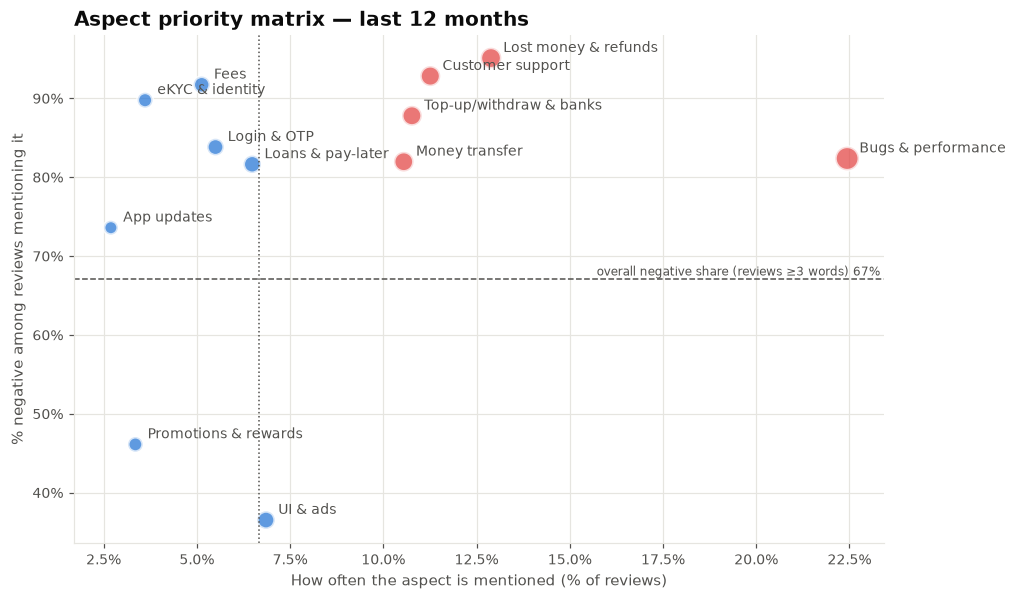

**Top-right (red) = high priority:** Bugs & performance, Lost money & refunds, Customer support, Top-up/withdraw & banks, Money transfer

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 6))
x, y = stats["mention_rate"], stats["negative_share"]
hot = (y > base_neg) & (x > x.median())
ax.scatter(x, y, s=np.sqrt(stats["reviews"]) * 6, c=np.where(hot, SENTIMENT_COLORS["negative"], BLUE),
           alpha=0.75, edgecolor="white", linewidth=2)
# Place labels without overlap: try candidate offsets, skip any that collide with labels already placed
fig.canvas.draw(); placed = []
for name, xi, yi in sorted(zip(stats.index, x, y), key=lambda t: -t[2]):
    px, py = ax.transData.transform((xi, yi))
    for dx, dy in [(8, 4), (8, -14), (-8, 4), (-8, -14), (8, 16)]:
        w = 6.5 * len(name)
        box = (px + dx - (w if dx < 0 else 0), py + dy, w, 12)
        if not any(abs(box[0] - b[0]) < (w + b[2]) / 2 + 4 and abs(box[1] - b[1]) < 13 for b in placed):
            break
    placed.append(box)
    ax.annotate(name, (xi, yi), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=INK_2,
                ha="right" if dx < 0 else "left")
ax.axhline(base_neg, color=INK_2, linestyle="--", linewidth=1)
ax.axvline(x.median(), color=INK_2, linestyle=":", linewidth=1)
ax.text(ax.get_xlim()[1], base_neg, f"overall negative share (reviews ≥3 words) {base_neg:.0%} ",
        ha="right", va="bottom", fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("How often the aspect is mentioned (% of reviews)"); ax.set_ylabel("% negative among reviews mentioning it")
ax.set_title("Aspect priority matrix — last 12 months")
save(fig, "03_aspect_priority_matrix"); plt.show()
display(Markdown("**Top-right (red) = high priority:** " + ", ".join(stats.index[hot])))

## 4. How negative aspects evolve over time

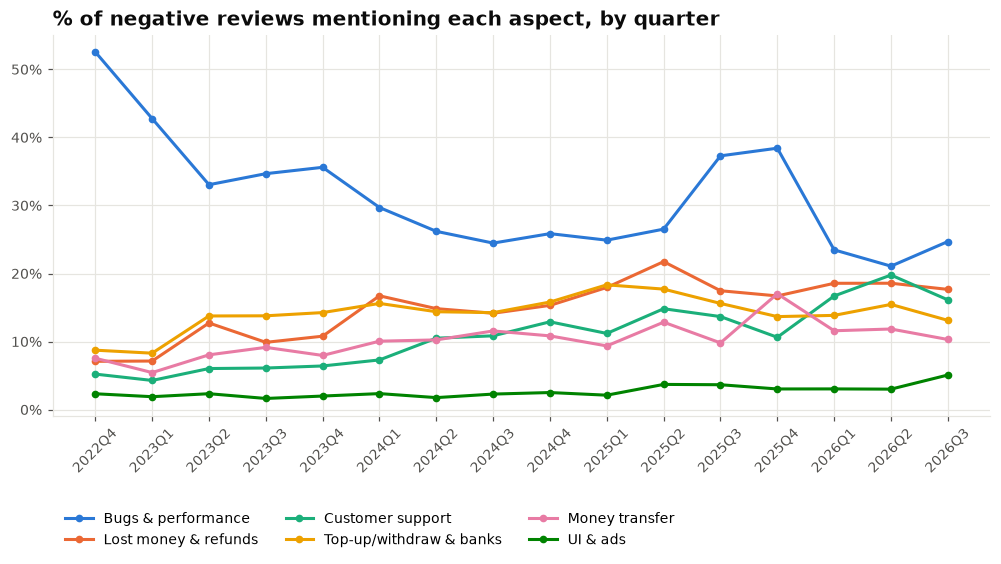

In [7]:
neg_a = df_a[(df_a["sentiment"] == "negative") & (df_a["at"] >= df_a["at"].max() - pd.DateOffset(years=4))]
trend = neg_a.groupby(neg_a["at"].dt.to_period("Q"))[list(ASPECTS)].mean()
trend = trend.iloc[:-1] if len(trend) > 1 else trend   # drop the unfinished quarter
top = stats.index[:6]
fig, ax = plt.subplots(figsize=(11, 4.5))
for a in top:
    ax.plot(trend.index.astype(str), trend[a], marker="o", markersize=4, label=a)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.tick_params(axis="x", rotation=45)
ax.set_title("% of negative reviews mentioning each aspect, by quarter")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22))
save(fig, "03_aspect_trend"); plt.show()

In [8]:
change = (trend.iloc[-2:].mean() - trend.iloc[-6:-2].mean()).sort_values(ascending=False)
display(Markdown("**Change in share (last 2 quarters vs. the 4 before), percentage points:**"))
(change * 100).round(1).to_frame("Δ pp")

**Change in share (last 2 quarters vs. the 4 before), percentage points:**

,Δ pp
Customer support,4.0
eKYC & identity,3.4
Fees,1.8
UI & ads,0.7
Loans & pay-later,0.5
Promotions & rewards,0.3
Login & OTP,-0.3
Lost money & refunds,-0.5
Top-up/withdraw & banks,-0.9
App updates,-1.1


## 5. Recommended actions (data-driven)

| Finding | Recommendation | KPI to track |
|---|---|---|
| Aspects in the red corner of the priority matrix | Put them at the top of the backlog; assign an owner per aspect | % of negative reviews mentioning the aspect, per release |
| Negative share spikes tied to specific versions (notebook 01) | Automatic post-release alert (daily z-score) | Time to detect an incident |
| 4–5★ reviews containing complaints (notebook 02) | Use the sentiment model to flag them for customer support | % of flagged reviews handled within 24h |
| Fast-rising aspects (table above) | Investigate root cause before they reach the red corner | Quarter-over-quarter change |

*Limitations:* keyword lists cannot catch every phrasing; Store reviews are a self-selected sample (very happy / very unhappy users write more) and do not represent all users.